# Финальный экзамен
Анализ данных в Python, Бояринов Олег

Данные: записи событий матчей плей-офф НХЛ сезона 2025/2026 (`NHL-playoffs-2026.xlsx`), 82 игры, 16 команд, 29 710 событий. Для рисования площадки используется выложенный с заданием модуль `rink.py`, он должен лежать рядом с тетрадью.

В тетради — код, краткие комментарии к нему и интерпретация результатов по каждому из 22 пунктов. Более подробные пояснения (как устроены данные, почему выбран тот или иной способ расчёта, обсуждение расхождений с примерами из условия) вынесены в отдельный отчёт `Отчёт_Бояринов.pdf`. При запуске рисунки дополнительно сохраняются в папку `figures`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from rink import plot_rink

# общий стиль и шрифт для всех рисунков
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.family": "serif", "font.serif": ["DejaVu Serif"], "font.size": 11})
pd.set_option("display.width", 120)
pd.set_option("display.precision", 3)
os.makedirs("figures", exist_ok=True)


def save(plot, name):
    figure = plot.figure if hasattr(plot, "figure") else plot
    for ext in ("pdf", "svg", "png"):
        figure.savefig(f"figures/{name}.{ext}", bbox_inches="tight", dpi=150)

## 1. Загрузка данных
В Excel-файле первый столбец — это сохранённый индекс pandas, поэтому читаем его как индекс (`index_col=0`), иначе колонок будет 39, а не 38.

In [2]:
events = pd.read_excel("NHL-playoffs-2026.xlsx", index_col=0)  # первый столбец — старый индекс
print(events.shape)
events.iloc[:10, [2, 3, 4, 9, 12]]

(29710, 38)


,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


У трёх игроков фамилии записаны с испорченной кодировкой: байты UTF-8 были прочитаны как Latin-1 (`SlafkovskÃ½` вместо `Slafkovský`). Ошибка одинаковая во всех колонках, поэтому на подсчёты она не влияет, но в выводе выглядит некрасиво — чиним обратным преобразованием.

In [3]:
def fix_encoding(text):
    try:
        return text.encode("latin-1").decode("utf-8")  # возвращаем байты и читаем их как UTF-8
    except (UnicodeEncodeError, UnicodeDecodeError):
        return text


text_columns = [c for c in events.columns if pd.api.types.is_string_dtype(events[c])]
before = set(pd.unique(events[text_columns].values.ravel()))
for column in text_columns:
    events[column] = events[column].map(fix_encoding, na_action="ignore")
after = set(pd.unique(events[text_columns].values.ravel()))
print("исправлено:", sorted(after - before))

исправлено: ['Juraj Slafkovský', 'Oskar Bäck', 'Tim Stützle']


Для ориентира — сколько событий каждого типа в данных:

In [4]:
events["Play Type"].value_counts()

Play Type
hit                5621
faceoff            4995
shot-on-goal       4137
stoppage           3958
blocked-shot       2798
missed-shot        2643
giveaway           2604
penalty             804
takeaway            779
goal                486
period-start        272
period-end          272
delayed-penalty     259
game-end             82
Name: count, dtype: int64

## 2. Сводная таблица по играм
Итоговый счёт — максимум накопленного счёта по событиям игры (он же счёт в последнем событии). Число овертаймов определяем по максимальному номеру периода: 3 — основное время, 4 — один овертайм, 5 — два.

In [5]:
games = events.groupby("Game ID").agg(**{
    "Date": ("Date", "first"),
    "Away Team": ("Away Team", "first"),
    "Home Team": ("Home Team", "first"),
    "Away Score": ("Cumulated Away Score", "max"),
    "Home Score": ("Cumulated Home Score", "max"),
    "Periods": ("Period", "max"),
})


def outcome(periods):
    # период 4 — овертайм, 5 — второй овертайм
    if periods <= 3:
        return "Final"
    if periods == 4:
        return "Final/OT"
    return f"Final/{periods - 3}OT"


games["Outcome"] = games["Periods"].map(outcome)
games = games.drop(columns="Periods")
print(games.columns)
games.iloc[-5:, -4:]

Index(['Date', 'Away Team', 'Home Team', 'Away Score', 'Home Score', 'Outcome'], dtype='str')


,Home Team,Away Score,Home Score,Outcome
Game ID,,,,
2025030412,Carolina Hurricanes,3,4,Final/OT
2025030413,Vegas Golden Knights,4,5,Final/2OT
2025030414,Vegas Golden Knights,5,3,Final
2025030415,Carolina Hurricanes,2,4,Final
2025030416,Vegas Golden Knights,3,0,Final


In [6]:
games["Outcome"].value_counts()

Outcome
Final        60
Final/OT     18
Final/2OT     4
Name: count, dtype: int64

Из 82 матчей 60 закончились в основное время, 18 — в первом овертайме и 4 — во втором. Больше двух овертаймов в этом плей-офф не было.

## 3. Функция `gameInfo`
Формат как в условии: хозяева — гости, счёт хозяев — счёт гостей, исход, дата.

In [7]:
def gameInfo(gameId):
    g = games.loc[gameId]
    return (f"{g['Home Team']} - {g['Away Team']} "
            f"({g['Home Score']} - {g['Away Score']}, {g['Outcome']}, {g['Date']})")


print(gameInfo(games.index.min()))
print(gameInfo(games.index.max()))

Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


## 4. Число голов в матче

In [8]:
games["Total Score"] = games["Away Score"] + games["Home Score"]
games["Total Score"].describe()

count    82.000
mean      5.927
std       2.260
min       1.000
25%       5.000
50%       6.000
75%       7.000
max      15.000
Name: Total Score, dtype: float64

## 5. Гистограмма числа голов
`countplot` рисует по одному столбику на каждое значение; чтобы значения без матчей (12, 13, 14) тоже были на оси, порядок категорий задаём явно.

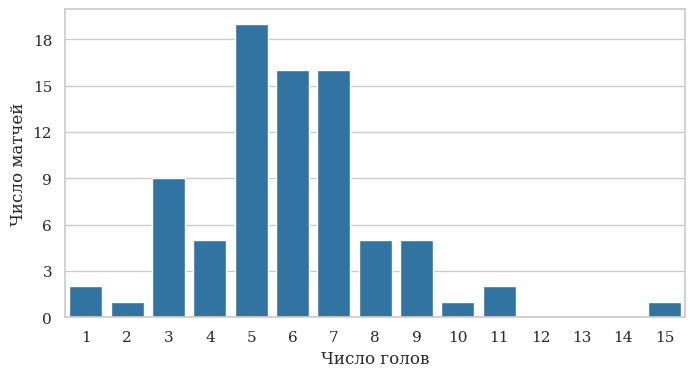

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(data=games, x="Total Score", color="tab:blue",
              order=range(games["Total Score"].min(), games["Total Score"].max() + 1), ax=ax)
ax.set_xlabel("Число голов")
ax.set_ylabel("Число матчей")
ax.set_yticks(range(0, 21, 3))
save(fig, "total_score_hist")

**Комментарий.** Чаще всего в матче забивают 5 шайб (19 матчей), почти так же часто 6 и 7 (по 16). Больше половины матчей укладываются в диапазон от 5 до 7 голов, среднее 5,9, медиана 6. Распределение несимметричное: слева оно обрывается быстро (меньше трёх голов — всего три матча: два закончились 1:0 в овертайме и один 2:0), а справа тянется хвост до 11 и один выброс — 15 шайб в матче Colorado — Minnesota (9:6). Это нормальная картина для плей-офф: игра осторожная, команды стараются не пропускать, и разгромы редки.

## 6. Самые нерезультативные и самые результативные матчи

In [10]:
total = games["Total Score"]
least_productive = [gameInfo(g) for g in games.index[total == total.min()]]
most_productive = [gameInfo(g) for g in games.index[total == total.max()]]
print(least_productive)
print(most_productive)

['Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)', 'Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)']
['Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)']


Оба самых «сухих» матча закончились со счётом 1:0 в овертайме, то есть в основное время никто не забил вообще. Самый результативный — Colorado — Minnesota 9:6.

## 7. Число игроков в матче
Собираем все колонки с игроками на льду (по шесть полевых и вратарь у каждой команды), вытягиваем их в один столбец и считаем уникальные фамилии в каждой игре.

In [11]:
on_ice = [c for c in events.columns if "Player on the Ice" in c or "Goalie" in c]

player_count = (events[["Game ID"] + on_ice]
                .melt(id_vars="Game ID", value_name="Player")  # все 14 колонок с игроками в одну
                .dropna()
                .groupby("Game ID")["Player"].nunique()
                .rename("Player Count")
                .to_frame())
player_count.insert(0, "Game Info", [gameInfo(g) for g in player_count.index])
player_count.nlargest(5, "Player Count")

,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...",40
2025030112,"Buffalo Sabres - Boston Bruins (2 - 4, Final, ...",39
2025030114,"Boston Bruins - Buffalo Sabres (1 - 6, Final, ...",39
2025030185,"Edmonton Oilers - Anaheim Ducks (4 - 1, Final,...",39
2025030215,"Buffalo Sabres - Montréal Canadiens (3 - 6, Fi...",39


In [12]:
player_count["Player Count"].value_counts().sort_index()

Player Count
38    73
39     8
40     1
Name: count, dtype: int64

**Комментарий.** В заявке на матч у команды 20 игроков: 18 полевых и 2 вратаря, но запасной вратарь обычно на лёд не выходит, поэтому типичное число участников — 38 (по 19 с каждой стороны), таких матчей 73 из 82. Больше игроков появляется, когда вратаря меняют по ходу игры.

Больше всего игроков — 40 — в матче Montréal — Buffalo (3:8). В примере из условия для этой же игры указано 41. Я проверил: ни полевых игроков с одинаковыми фамилиями, ни двух написаний одной фамилии в этой игре нет, 20 гостей и 20 хозяев. Лишняя единица в примере, скорее всего, появилась из-за того, что в множество имён попало пустое значение: в колонке шестого игрока оно стоит всякий раз, когда команда играет в меньшинстве. Подробнее — в отчёте.

## 8. Расстояние до ворот
Какие ворота атакует команда, зависит от двух полей: кто бросает (хозяева или гости) и где стоят ворота хозяев (`Home Team's Defending Side`). Хозяева при `left` бросают в правые ворота (X = 89), гости — в левые (X = −89); при `right` наоборот. Расстояние считаем до ближайшей точки створа шириной 6 футов, по формуле из условия.

In [13]:
SHOT_TYPES = ["shot-on-goal", "goal", "missed-shot"]

# ворота справа, если хозяева бросают при left или гости при right
shooter_is_home = events["Team Making the Play"] == events["Home Team"]
home_defends_left = events["Home Team's Defending Side"] == "left"
goal_x = np.where(shooter_is_home == home_defends_left, 89, -89)

# при |y| <= 3 расстояние до линии ворот, иначе до ближней штанги
x = events["X Coordinate on the Ice Rink"]
y = events["Y Coordinate on the Ice Rink"]
distance = np.select([y < -3, y > 3],
                     [np.hypot(x - goal_x, y + 3), np.hypot(x - goal_x, y - 3)],
                     default=np.abs(x - goal_x))
events["Shot Length"] = np.where(events["Play Type"].isin(SHOT_TYPES), distance, np.nan)

shots = events[events["Play Type"].isin(SHOT_TYPES)].copy()
shots["Shot"] = np.where(shots["Play Type"] == "missed-shot", "missed", "on goal")
shots[["Game ID", "Play Type", "Shot Length"]]

,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.207
9,2025030111,missed-shot,12.000
12,2025030111,missed-shot,29.411
13,2025030111,shot-on-goal,62.169
19,2025030111,missed-shot,52.924
...,...,...,...
29695,2025030416,missed-shot,54.083
29696,2025030416,missed-shot,5.099
29704,2025030416,goal,46.239
29706,2025030416,missed-shot,60.926


In [14]:
shots.groupby("Shot")["Shot Length"].describe()

,count,mean,std,min,25%,50%,75%,max
Shot,,,,,,,,
missed,2643.0,34.014,22.313,0.0,16.155,32.249,49.041,185.068
on goal,4623.0,36.207,29.997,0.0,15.000,31.828,47.011,188.215


## 9. Распределение длины точных и неточных бросков
Точных бросков (4623) почти вдвое больше, чем неточных (2643), поэтому сравнивать нужно не количества, а плотности: `stat="density"` и `common_norm=False`, чтобы каждая группа нормировалась отдельно.

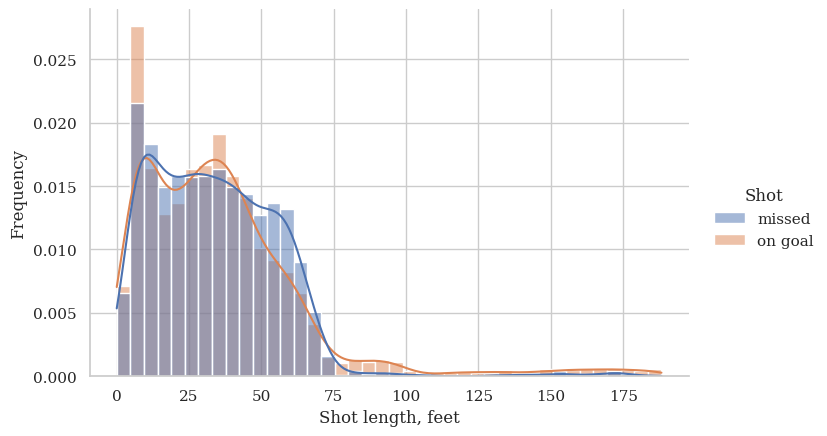

In [15]:
g = sns.displot(data=shots, x="Shot Length", hue="Shot", hue_order=["missed", "on goal"],
                stat="density", common_norm=False, kde=True, bins=40, height=4.5, aspect=1.6)
g.set_axis_labels("Shot length, feet", "Frequency")
save(g, "shot_length_hist")

Чтобы понять, откуда берётся хвост бросков дальше 100 футов (со своей половины площадки), посмотрим, когда они сделаны. Выделим типичную ситуацию «пустые ворота»: последние три минуты третьего периода, бросающая команда ведёт в счёте — именно тогда соперник снимает вратаря.

In [16]:
long_shots = shots[shots["Shot Length"] > 100].copy()
minutes, seconds = long_shots["Remaining Time"].str.split(":", expand=True).astype(int).values.T
shooter_is_home = long_shots["Team Making the Play"] == long_shots["Home Team"]
lead = np.where(shooter_is_home,
                long_shots["Cumulated Home Score"] - long_shots["Cumulated Away Score"],
                long_shots["Cumulated Away Score"] - long_shots["Cumulated Home Score"])
lead_before_shot = lead - (long_shots["Play Type"] == "goal")
# концовка третьего периода при своём лидерстве — соперник снял вратаря
empty_net_time = (long_shots["Period"] == 3) & (minutes * 60 + seconds <= 180) & (lead_before_shot >= 1)
situation = np.where(empty_net_time, "концовка, бросающие ведут", "обычное игровое время")
pd.crosstab(long_shots["Play Type"], situation, margins=True)

col_0,"концовка, бросающие ведут",обычное игровое время,All
Play Type,,,
goal,14,3,17
missed-shot,16,7,23
shot-on-goal,1,142,143
All,31,152,183


In [17]:
long_shots[~empty_net_time]["Period"].value_counts().sort_index()

Period
1    53
2    49
3    41
4     8
5     1
Name: count, dtype: int64

**Комментарий.** В основной части (до 75 футов, то есть примерно до синей линии) распределения очень похожи: обе группы имеют пик около 10–15 футов и второй, пошире, около 30–40 футов. Отличия небольшие: точные броски чуть чаще совсем с близкого расстояния (добивания у ворот), а неточные — чуть чаще с 50–70 футов, то есть от синей линии: бросок издалека чаще летит мимо. Иными словами, дистанция сама по себе слабо отличает точный бросок от неточного.

Зато дальше 100 футов картина резко разная: таких точных бросков 160, а неточных всего 23. Таблица показывает, что это две разные группы событий.

Первая — пустые ворота: 14 голов и 16 промахов сделаны в последние три минуты третьего периода командой, которая вела в счёте. Соперник снял вратаря, и бросок через всю площадку по пустым воротам либо становится голом, либо записывается как промах.

Вторая группа гораздо больше — 142 дальних броска в створ в обычное игровое время, равномерно во всех периодах. Это не попытки забить, а выбросы шайбы из своей зоны, которые долетели до вратаря соперника: по правилам учёта НХЛ любой бросок, который вратарь отбил или поймал, записывается как бросок в створ. А выброс, который ушёл мимо ворот, броском не считается вовсе — это проброс или просто смена зоны, событие с другим типом. Отсюда и асимметрия: дальний бросок попадает в данные почти только тогда, когда он «точный». То есть длинный хвост точных бросков — это артефакт правил регистрации событий, а не свидетельство меткости хоккеистов.

## 10. Доля точных бросков среди незаблокированных
Незаблокированные броски — это `shot-on-goal`, `goal` и `missed-shot`; точные — первые два.

In [18]:
numshots = shots.groupby(["Game ID", "Team Making the Play"]).agg(**{
    "Unblocked Shots": ("Shot", "size"),
    "Shots on Goal": ("Shot", lambda s: (s == "on goal").sum()),
})
numshots["Share of Shots on Goal"] = numshots["Shots on Goal"] / numshots["Unblocked Shots"]
numshots["Share of Shots on Goal"]

Game ID     Team Making the Play
2025030111  Boston Bruins           0.625
            Buffalo Sabres          0.679
2025030112  Boston Bruins           0.614
            Buffalo Sabres          0.636
2025030113  Boston Bruins           0.694
                                    ...  
2025030414  Vegas Golden Knights    0.583
2025030415  Carolina Hurricanes     0.558
            Vegas Golden Knights    0.510
2025030416  Carolina Hurricanes     0.639
            Vegas Golden Knights    0.595
Name: Share of Shots on Goal, Length: 164, dtype: float64

In [19]:
numshots["Share of Shots on Goal"].describe()

count    164.000
mean       0.639
std        0.085
min        0.353
25%        0.583
50%        0.639
75%        0.689
max        0.860
Name: Share of Shots on Goal, dtype: float64

**Комментарий.** В среднем около 64% незаблокированных бросков попадают в створ, то есть примерно каждый третий бросок летит мимо. Разброс между матчами большой — от 0,35 до 0,86, — но это во многом случайность: за матч команда наносит 35–45 незаблокированных бросков, и при такой выборке доля колеблется на ±10 процентных пунктов просто от игры к игре. Поэтому по одному матчу судить о «точности» команды нельзя, нужно усреднять по серии, что и делается в следующем пункте.

## 11. Команды с самой высокой и самой низкой долей точных бросков

In [20]:
avgnumshots = numshots.groupby("Team Making the Play")["Share of Shots on Goal"].mean()
print(avgnumshots.nlargest(5))
print(avgnumshots.nsmallest(5))

Team Making the Play
Edmonton Oilers        0.706
Philadelphia Flyers    0.684
Dallas Stars           0.670
Minnesota Wild         0.656
Colorado Avalanche     0.653
Name: Share of Shots on Goal, dtype: float64
Team Making the Play
Pittsburgh Penguins    0.554
Utah Mammoth           0.599
Carolina Hurricanes    0.615
Tampa Bay Lightning    0.626
Buffalo Sabres         0.626
Name: Share of Shots on Goal, dtype: float64


**Комментарий.** Разница между лучшей и худшей командой — 15 процентных пунктов: у Edmonton в створ летит 71% бросков, у Pittsburgh — 55%. При этом внутри первой пятёрки и внутри последней различия уже невелики, и значительная часть разброса объясняется короткими выборками: команды, вылетевшие в первом раунде, сыграли по 4–7 матчей. Доля точных бросков говорит не столько о мастерстве, сколько о стиле: команды, которые бросают с близкого расстояния и из опасных зон, попадают в створ чаще, а команды, бросающие издалека и много, — реже. Показательно, что в верхней пятёрке Colorado и Minnesota — лидеры по результативности, а в нижней — Pittsburgh и Tampa, забивавшие мало.

## 12. Среднее число бросков в створ и голов за игру
Гол в НХЛ тоже считается броском в створ, поэтому колонка `Shot` включает и `shot-on-goal`, и `goal`.

In [21]:
on_goal = shots[shots["Shot"] == "on goal"]
avgshots = (on_goal.groupby(["Game ID", "Team Making the Play"])
            .agg(Shot=("Play Type", "size"), Goal=("Play Type", lambda s: (s == "goal").sum()))
            .groupby("Team Making the Play").mean())
avgshots

,Shot,Goal
Team Making the Play,,
Anaheim Ducks,31.667,3.250
Boston Bruins,25.167,2.000
Buffalo Sabres,30.462,3.308
Carolina Hurricanes,31.632,3.474
Colorado Avalanche,32.154,3.385
Dallas Stars,31.000,2.500
Edmonton Oilers,28.333,3.500
Los Angeles Kings,25.250,1.250
Minnesota Wild,28.727,3.727


## 13. Связь бросков в створ и голов

корреляция 0.521, наклон 0.156 гола на один бросок


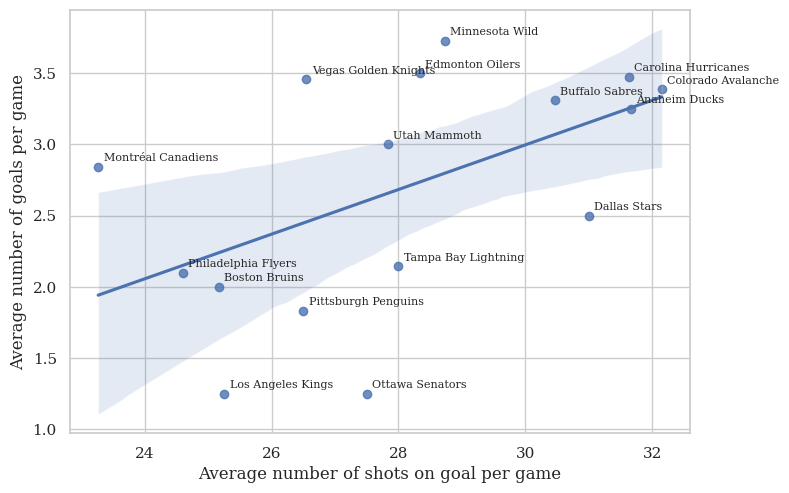

In [22]:
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.regplot(data=avgshots, x="Shot", y="Goal", ax=ax)
for team, row in avgshots.iterrows():
    ax.annotate(team, (row["Shot"], row["Goal"]), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set_xlabel("Average number of shots on goal per game")
ax.set_ylabel("Average number of goals per game")
save(fig, "shots_vs_goals")

slope, intercept = np.polyfit(avgshots["Shot"], avgshots["Goal"], 1)
print(f"корреляция {avgshots['Shot'].corr(avgshots['Goal']):.3f}, наклон {slope:.3f} гола на один бросок")

**Комментарий.** Связь есть, но слабая. Прямая идёт вверх: каждый дополнительный бросок в створ за игру в среднем добавляет около 0,16 гола, корреляция 0,52. Но доверительная полоса широкая, и точки сильно разбросаны вокруг прямой. Ottawa и Los Angeles при среднем числе бросков забивали по 1,25 гола за игру, а Vegas с таким же числом бросков — 3,45. Разница между ними не в количестве бросков, а в их качестве и в игре вратарей соперника: процент реализации у Vegas был почти втрое выше (13% против 4,5%). На 16 точках такой разброс не позволяет говорить о надёжной зависимости — количество бросков объясняет лишь около четверти различий в результативности.

## 14. Матч с наибольшим числом ударов по воротам
Считаем все попытки броска: точные, неточные и заблокированные.

In [23]:
ALL_SHOT_TYPES = SHOT_TYPES + ["blocked-shot"]
shots_per_game = events[events["Play Type"].isin(ALL_SHOT_TYPES)].groupby("Game ID").size()
idxmax = shots_per_game.idxmax()
print(shots_per_game.max(), "ударов")
gameInfo(idxmax)

208 ударов


'Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)'

Неудивительно, что это матч с двумя овертаймами: игра длилась почти пять периодов вместо трёх.

## 15. Карта бросков
Гостей рисуем бьющими в левые ворота, хозяев — в правые. В этом матче хозяева защищают правые ворота в нечётных периодах, поэтому именно в них координаты отражаем: (x, y) → (−x, −y). Чтобы код не зависел от конкретного матча, условие записано через поле `Home Team's Defending Side`: отражаем, когда хозяева защищают правые ворота.

{1: 'right', 2: 'left', 3: 'right', 4: 'left', 5: 'right'}


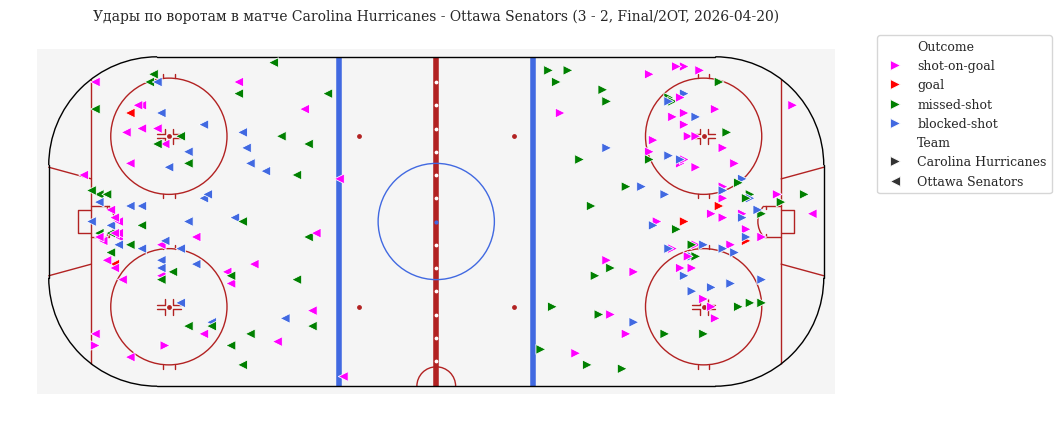

In [24]:
game = events[(events["Game ID"] == idxmax) & events["Play Type"].isin(ALL_SHOT_TYPES)].copy()
print(game.groupby("Period")["Home Team's Defending Side"].first().to_dict())

# отражаем координаты там, где хозяева защищают правые ворота
flip = game["Home Team's Defending Side"] == "right"
game["x"] = np.where(flip, -game["X Coordinate on the Ice Rink"], game["X Coordinate on the Ice Rink"])
game["y"] = np.where(flip, -game["Y Coordinate on the Ice Rink"], game["Y Coordinate on the Ice Rink"])
game = game.rename(columns={"Play Type": "Outcome", "Team Making the Play": "Team"})

home, away = games.loc[idxmax, "Home Team"], games.loc[idxmax, "Away Team"]
fig = plt.figure(figsize=(11, 5))
plot_rink()
sns.scatterplot(data=game, x="x", y="y", hue="Outcome", hue_order=ALL_SHOT_TYPES,
                palette={"goal": "red", "shot-on-goal": "magenta", "blocked-shot": "royalblue", "missed-shot": "green"},
                style="Team", markers={home: ">", away: "<"}, s=50)  # треугольник вправо — хозяева, влево — гости
plt.axis("equal")
plt.axis("off")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=9)
plt.title(f"Удары по воротам в матче {gameInfo(idxmax)}", fontsize=10)
save(fig, "rink_shots")

In [25]:
pd.crosstab(game["Team"], game["Outcome"], margins=True)

Outcome,blocked-shot,goal,missed-shot,shot-on-goal,All
Team,,,,,
Carolina Hurricanes,26,3,34,46,109
Ottawa Senators,28,2,32,37,99
All,54,5,66,83,208


**Комментарий.** После отражения броски Ottawa (гости, треугольники влево) собрались у левых ворот, а броски Carolina (хозяева, треугольники вправо) — у правых, как и требовалось. Carolina бросала больше (109 попыток против 99) и чаще попадала в створ (46 против 37), её броски плотнее сгруппированы перед воротами. У обеих команд заметна полоса заблокированных и неточных бросков от синей линии. Голов на карте всего пять за почти пять периодов, и все они из ближней зоны — ещё одна иллюстрация к пункту 9: издалека в плей-офф почти не забивают.

## 16. Лучшие снайперы

In [26]:
P1, P2, P3 = "Player in the Event #1", "Player in the Event #2", "Player in the Event #3"
goals = events[events["Play Type"] == "goal"]

scorers = goals[P1].value_counts().rename("Goals")
scorers.head(10)

Player in the Event #1
Brett Howden        14
Pavel Dorofeyev     12
Logan Stankoven     11
Mitch Marner        10
Nikolaj Ehlers       8
Jordan Staal         8
Alex Newhook         7
Taylor Hall          7
Jackson Blake        7
Nathan MacKinnon     7
Name: Goals, dtype: int64

## 17. Лучшие ассистенты
Передачи — это второй и третий игрок в событии «гол». Складываем оба столбца.

In [27]:
assists = pd.concat([goals[P2], goals[P3]]).value_counts().rename("Assists")
assists.head(10)

Jack Eichel        20
Mitch Marner       19
Lane Hutson        13
Jackson Blake      13
Nick Suzuki        12
Taylor Hall        12
Martin Necas       12
Shea Theodore      12
Kirill Kaprizov    11
Quinn Hughes       11
Name: Assists, dtype: int64

## 18. Очки «гол + пас»

In [28]:
points = pd.concat([scorers, assists], axis=1).fillna(0).astype(int)
points["Points"] = points["Goals"] + points["Assists"]
points.sort_values("Points", ascending=False).head(10)

,Goals,Assists,Points
Mitch Marner,10,19,29
Jack Eichel,2,20,22
Jackson Blake,7,13,20
Taylor Hall,7,12,19
Brett Howden,14,4,18
Shea Theodore,6,12,18
Nikolaj Ehlers,8,10,18
Lane Hutson,3,13,16
Nick Suzuki,4,12,16
Pavel Dorofeyev,12,4,16


**Комментарий.** Лучший бомбардир плей-офф — Mitch Marner, 29 очков (10+19), с отрывом в семь очков от Jack Eichel. Оба из Vegas, как и Brett Howden, лучший снайпер с 14 голами, и Pavel Dorofeyev. Vegas дошёл до финала, поэтому его игроки провели больше всех матчей и имели больше возможностей набирать очки; Из Carolina, второго финалиста, в десятке бомбардиров Jackson Blake, Taylor Hall и Nikolaj Ehlers, а Jordan Staal входит в десятку снайперов.

## 19. Броски в створ за игру
Число сыгранных матчей для каждого игрока берём из колонок «игроки на льду»: игрок участвовал в матче, если хотя бы раз был на льду.

In [29]:
# сыгранные матчи: в скольких играх игрок появлялся на льду
appearances = events[["Game ID"] + on_ice].melt(id_vars="Game ID", value_name="Player").dropna()
games_played = appearances.groupby("Player")["Game ID"].nunique().rename("Games")

player_shots = pd.concat([on_goal[P1].value_counts().rename("Shots on Goal"), games_played], axis=1, join="inner")
player_shots["Shots on Goal per Game"] = player_shots["Shots on Goal"] / player_shots["Games"]
player_shots.sort_values("Shots on Goal per Game", ascending=False).head(10)

,Shots on Goal,Games,Shots on Goal per Game
Jason Robertson,30,6,5.000
Dylan Guenther,27,6,4.500
Nikita Kucherov,31,7,4.429
Matt Boldy,48,11,4.364
Quinton Byfield,17,4,4.250
Darren Raddysh,28,7,4.000
Joel Eriksson Ek,24,6,4.000
Alex Laferriere,15,4,3.750
David Pastrnak,22,6,3.667
Nathan MacKinnon,47,13,3.615


## 20. Силовые приёмы за игру

In [30]:
hits = events[events["Play Type"] == "hit"]
player_hits = pd.concat([hits[P1].value_counts().rename("Hits"), games_played], axis=1, join="inner")
player_hits["Hits per Game"] = player_hits["Hits"] / player_hits["Games"]
player_hits.sort_values("Hits per Game", ascending=False).head(10)

,Hits,Games,Hits per Game
Lawson Crouse,38,6,6.333
Alexander Petrovic,6,1,6.000
Alex Turcotte,6,1,6.000
Yakov Trenin,51,9,5.667
Dylan Cozens,22,4,5.500
Vasily Podkolzin,32,6,5.333
Ivan Barbashev,110,22,5.000
Carl Grundstrom,15,3,5.000
Marcus Foligno,55,11,5.000
Owen Tippett,29,6,4.833


**Комментарий.** Среди бросающих лидирует Jason Robertson (5 бросков в створ за игру), среди силовиков — Lawson Crouse (6,3 приёма за игру). В обоих списках много игроков команд, вылетевших в первом раунде: у них всего 4–7 матчей, и средние по короткой выборке получаются экстремальнее. Поэтому рядом с показателем выведено число игр.

## 21. Вратари с «сухими» матчами
Для каждого гола определяем пропустившего вратаря — это вратарь команды, которой забили, стоявший на льду в момент гола. Если вратаря на льду не было (гол в пустые ворота), гол никому не засчитывается.

Здесь есть ловушка в данных. У 111 событий поля о составах на льду не заполнены (число игроков 0, вратари пустые), и среди них — все 22 победных гола в овертаймах. Если этого не учесть, овертаймовые голы никому не засчитаются и четыре вратаря получат «сухие» матчи, в которых они на самом деле пропустили решающий гол. Поэтому для событий без данных о составе берём вратаря из предыдущего события той же игры.

In [31]:
# события без составов — среди них все голы в овертаймах
no_lineup = (events["# of Away Team's Players on the Ice"] == 0) & (events["# of Home Team's Players on the Ice"] == 0)
print(no_lineup.sum(), "событий без данных о составе:", events.loc[no_lineup, "Play Type"].value_counts().to_dict())
print("голов в овертаймах:", (goals["Period"] > 3).sum(), "| из них без данных о составе:", no_lineup[goals.index].sum())

# восстанавливаем вратаря по предыдущему событию той же игры
goalies_filled = events.groupby("Game ID")[["Away Team's Goalie", "Home Team's Goalie"]].ffill()
away_goalie = events["Away Team's Goalie"].where(~no_lineup, goalies_filled["Away Team's Goalie"])
home_goalie = events["Home Team's Goalie"].where(~no_lineup, goalies_filled["Home Team's Goalie"])

111 событий без данных о составе: {'period-end': 36, 'game-end': 31, 'goal': 22, 'penalty': 19, 'stoppage': 3}
голов в овертаймах: 22 | из них без данных о составе: 22


In [32]:
# пропустил вратарь той команды, которой забили
scoring_team_is_home = goals["Team Making the Play"] == goals["Home Team"]
beaten_goalie = np.where(scoring_team_is_home, away_goalie[goals.index], home_goalie[goals.index])
goals_against = (pd.DataFrame({"Game ID": goals["Game ID"], "Goalie": beaten_goalie})
                 .dropna().groupby(["Game ID", "Goalie"]).size().rename("Goals Against"))
print("голов в пустые ворота (никому не засчитаны):", pd.isna(beaten_goalie).sum())

goalie_games = pd.concat([
    events[["Game ID", "Away Team's Goalie"]].set_axis(["Game ID", "Goalie"], axis=1),
    events[["Game ID", "Home Team's Goalie"]].set_axis(["Game ID", "Goalie"], axis=1),
]).dropna().groupby(["Game ID", "Goalie"]).size().rename("Events on Ice").to_frame()
goalie_games["Share of Game"] = goalie_games["Events on Ice"] / events.groupby("Game ID").size().reindex(goalie_games.index.get_level_values(0)).values
goalie_games["Goals Against"] = goals_against.reindex(goalie_games.index).fillna(0).astype(int)

shutouts = goalie_games[goalie_games["Goals Against"] == 0].reset_index()
shutouts.insert(1, "Game Info", shutouts["Game ID"].map(gameInfo))
shutouts.sort_values(["Goalie", "Game ID"]).set_index(["Goalie", "Game ID"])

голов в пустые ворота (никому не засчитаны): 3


Game Info  Events on Ice  Share of Game  \
Goalie             Game ID                                                                                       
Andrei Vasilevskiy 2025030126  Montréal Canadiens - Tampa Bay Lightning (0 - ...            391          0.992   
Brandon Bussi      2025030416  Vegas Golden Knights - Carolina Hurricanes (0 ...            343          1.000   
Dan Vladar         2025030142  Pittsburgh Penguins - Philadelphia Flyers (0 -...            390          1.000   
                   2025030146  Philadelphia Flyers - Pittsburgh Penguins (1 -...            385          0.987   
Frederik Andersen  2025030131  Carolina Hurricanes - Ottawa Senators (2 - 0, ...            370          0.989   
                   2025030221  Carolina Hurricanes - Philadelphia Flyers (3 -...            359          1.000   
                   2025030314  Montréal Canadiens - Carolina Hurricanes (0 - ...            389          1.000   
Joonas Korpisalo   2025030114  Boston Bruins - Buffalo Sabres (1 - 6, Final, ...             85          0.237   
Scott Wedgewood    2025030235  Colorado Avalanche - Minnesota Wild (4 - 3, Fi...            237          0.637   

                               Goals Against  
Goalie             Game ID                    
Andrei Vasilevskiy 2025030126              0  
Brandon Bussi      2025030416              0  
Dan Vladar         2025030142              0  
                   2025030146              0  
Frederik Andersen  2025030131              0  
                   2025030221              0  
                   2025030314              0  
Joonas Korpisalo   2025030114              0  
Scott Wedgewood    2025030235              0

In [33]:
print(sorted(shutouts["Goalie"].unique()))
print(len(shutouts["Goalie"].unique()), "вратарей,", len(shutouts), "матчей без пропущенных голов")

['Andrei Vasilevskiy', 'Brandon Bussi', 'Dan Vladar', 'Frederik Andersen', 'Joonas Korpisalo', 'Scott Wedgewood']
6 вратарей, 9 матчей без пропущенных голов


**Комментарий.** Матчей без пропущенных голов 9, их провели 6 вратарей. Три «сухаря» у Frederik Andersen (Carolina), два у Dan Vladar (Philadelphia), включая победу 1:0 в овертайме, по одному у Andrei Vasilevskiy (тоже 1:0 в овертайме), Brandon Bussi (финальный матч 3:0) и ещё у двоих. Два случая из девяти — не полноценные «сухари»: Joonas Korpisalo и Scott Wedgewood выходили на замену и провели на льду лишь часть матча (доля событий 0,2 и 0,6), но по условию такие случаи тоже считаются. Голы в пустые ворота вратарям не засчитаны: в этот момент их на льду не было.

## 22. Свой вопрос: есть ли в плей-офф преимущество своего льда?
Считается, что дома играть легче: своя публика, последняя смена, привычная арена. Проверим на этих данных, выигрывают ли хозяева чаще, и отличается ли их игра от игры гостей по броскам, силовым приёмам и удалениям.

In [34]:
games["Home Win"] = games["Home Score"] > games["Away Score"]
games["Round"] = games.index % 1000 // 100  # раунд — третья цифра с конца в Game ID
print(f"хозяева выиграли {games['Home Win'].sum()} матчей из {len(games)} ({games['Home Win'].mean():.1%})")

by_round = games.groupby("Round")["Home Win"].agg(["mean", "size"]).set_axis(["Home Win Share", "Games"], axis=1)
by_overtime = games.groupby(games["Outcome"] == "Final")["Home Win"].agg(["mean", "size"]).set_axis(["Home Win Share", "Games"], axis=1)
by_overtime.index = ["с овертаймом", "в основное время"]
print(by_round)
print(by_overtime)

хозяева выиграли 39 матчей из 82 (47.6%)
       Home Win Share  Games
Round                       
1               0.467     45
2               0.500     22
3               0.444      9
4               0.500      6
                  Home Win Share  Games
с овертаймом               0.636     22
в основное время           0.417     60


In [35]:
per_game = (events[events["Play Type"].isin(["shot-on-goal", "goal", "missed-shot", "blocked-shot", "hit", "penalty"])]
            .assign(Side=lambda d: np.where(d["Team Making the Play"] == d["Home Team"], "Home", "Away"))
            .groupby(["Game ID", "Side", "Play Type"]).size()
            .unstack(fill_value=0))
home_vs_away = per_game.groupby("Side").mean().T
home_vs_away["Difference"] = home_vs_away["Home"] - home_vs_away["Away"]
home_vs_away

Side,Away,Home,Difference
Play Type,,,
blocked-shot,16.280,17.841,1.561
goal,3.122,2.805,-0.317
hit,32.049,36.500,4.451
missed-shot,15.878,16.354,0.476
penalty,4.890,4.915,0.024
shot-on-goal,24.915,25.537,0.622


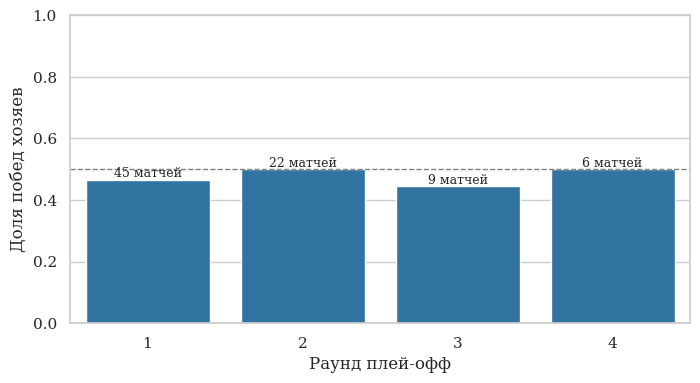

In [36]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=by_round.reset_index(), x="Round", y="Home Win Share", color="tab:blue", ax=ax)
ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
for i, row in by_round.reset_index().iterrows():
    ax.annotate(f"{row['Games']:.0f} матчей", (i, row["Home Win Share"]), ha="center", va="bottom", fontsize=9)
ax.set_xlabel("Раунд плей-офф")
ax.set_ylabel("Доля побед хозяев")
ax.set_ylim(0, 1)
save(fig, "home_advantage")

**Ответ.** Преимущества своего льда в этом плей-офф не видно. Хозяева выиграли 39 матчей из 82 — меньше половины. По раундам: 47% в первом, 50% во втором, 44% в финалах конференций и 50% в финале; ни одно из этих отклонений от 50% при таком числе игр не выходит за рамки случайности. Хозяева даже забивали в среднем меньше гостей: 2,8 гола за матч против 3,1. Единственное место, где они выглядят сильнее, — овертаймы: 14 побед из 22, но и это на 22 матчах не доказательство.

По игровым показателям хозяева и гости тоже почти не отличаются: бросков в створ у хозяев больше лишь на 0,6 за матч, заблокированных бросков на 1,6, удалений поровну. Единственная заметная разница — силовые приёмы: хозяевам записывают 36,5 за матч, гостям 32,0. Это известный эффект учёта: силовой приём — субъективное событие, и статистики на домашней арене охотнее засчитывают его своим. Так что и эта разница говорит скорее о регистрации событий, чем об игре. В плей-офф встречаются команды близкого уровня, и фактор домашней арены теряется на фоне разницы в классе и везения в конкретном матче.

## Итоги
Все примеры из условия воспроизведены: размер таблицы, сводка по играм, описательные статистики, расстояния до ворот, доли точных бросков, средние броски и голы по командам, матч с наибольшим числом ударов. Единственное расхождение — число игроков в матче Montréal — Buffalo (40 против 41 в примере), его разбор в пункте 7 и в отчёте.

Главные наблюдения: типичный матч плей-офф — 5–7 голов; расстояние броска почти не влияет на то, попадёт ли он в створ, а длинный хвост дальних точных бросков — это броски по пустым воротам; связь между количеством бросков и голами есть, но слабая, качество бросков и вратари важнее; преимущества своего льда в плей-офф 2026 года не обнаружено.